<a href="https://colab.research.google.com/github/Devil-92/Predicting_Airline_Satisfaction/blob/main/Notebook/Predicting_Airline_Satisfaction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

In [12]:
import os

In [20]:
%cd "/content/drive/MyDrive/Projects"

/content/drive/MyDrive/Projects


In [21]:
!mkdir -p 'Predicting Airline Satisfaction'

In [18]:
import os
os.environ['KAGGLEHUB_CACHE'] = "/content/drive/MyDrive/Projects/Predicting Airline Satisfaction"

In [19]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('playground-series-s6e10')

print("Path to competition files:", path)

100%|██████████| 15.1M/15.1M [00:00<00:00, 84.7MB/s]

Extracting files...


Path to competition files: /content/drive/MyDrive/Projects/Predicting Airline Satisfaction/competitions/playground-series-s6e10


In [59]:
train_df = pd.read_csv('/content/drive/MyDrive/Projects/Predicting Airline Satisfaction/competitions/playground-series-s6e10/train.csv')

In [60]:
test_df = pd.read_csv('/content/drive/MyDrive/Projects/Predicting Airline Satisfaction/competitions/playground-series-s6e10/test.csv')

In [61]:
train_df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [62]:
train_id = train_df.id
test_id = test_df.id

In [63]:
train_df.drop('id' , axis = 1 , inplace = True)
test_df.drop('id' , axis = 1 , inplace = True)

In [64]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                699635 non-null  int64  
 1   Flight Distance                    699635 non-null  int64  
 2   Inflight wifi service              699635 non-null  int64  
 3   Departure/Arrival time convenient  699635 non-null  int64  
 4   Ease of Online booking             699635 non-null  int64  
 5   Gate location                      699635 non-null  int64  
 6   Food and drink                     699635 non-null  int64  
 7   Online boarding                    699635 non-null  int64  
 8   Seat comfort                       699635 non-null  int64  
 9   Inflight entertainment             699635 non-null  int64  
 10  On-board service                   699635 non-null  int64  
 11  Leg room service                   6996

In [65]:
train_df.satisfaction.value_counts()

,count
satisfaction,
False,389296
True,310339


In [66]:
y = train_df.satisfaction
train_df.drop('satisfaction' , axis = 1 , inplace = True)
X = train_df

In [67]:
X.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,...,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,56,651,5,5,5,5,5,4,4,5,...,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,31,1371,3,4,2,5,3,3,3,3,...,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,10,1616,3,5,3,3,3,3,3,3,...,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,23,481,3,4,3,4,5,3,5,5,...,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco


In [68]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                699635 non-null  int64  
 1   Flight Distance                    699635 non-null  int64  
 2   Inflight wifi service              699635 non-null  int64  
 3   Departure/Arrival time convenient  699635 non-null  int64  
 4   Ease of Online booking             699635 non-null  int64  
 5   Gate location                      699635 non-null  int64  
 6   Food and drink                     699635 non-null  int64  
 7   Online boarding                    699635 non-null  int64  
 8   Seat comfort                       699635 non-null  int64  
 9   Inflight entertainment             699635 non-null  int64  
 10  On-board service                   699635 non-null  int64  
 11  Leg room service                   6996

In [69]:
for col in X.select_dtypes('object') :
  X[col] = X[col].astype('category')

In [70]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype   
---  ------                             --------------   -----   
 0   Age                                699635 non-null  int64   
 1   Flight Distance                    699635 non-null  int64   
 2   Inflight wifi service              699635 non-null  int64   
 3   Departure/Arrival time convenient  699635 non-null  int64   
 4   Ease of Online booking             699635 non-null  int64   
 5   Gate location                      699635 non-null  int64   
 6   Food and drink                     699635 non-null  int64   
 7   Online boarding                    699635 non-null  int64   
 8   Seat comfort                       699635 non-null  int64   
 9   Inflight entertainment             699635 non-null  int64   
 10  On-board service                   699635 non-null  int64   
 11  Leg room service          

In [71]:
y.head()

,satisfaction
0,False
1,True
2,False
3,False
4,False


In [74]:
## y.map({"False" : 0 , "True" : 1})          We cannot use this as python will detect T F as string and make the whole y as nan
y = y.map({False : 0 , True : 1})

In [76]:
print("The fastest way to do so is to use y.astype('int')")

The fastest way to do so is to use y.astype('int')


In [77]:
y.head()

,satisfaction
0,0
1,1
2,0
3,0
4,0


In [79]:
print('Before fitting to lgbm we need to ensure that the columns are all bool , int , float or category')

Before fitting to lgbm we need to ensure that the columns are all bool , int , float or category


In [78]:
from sklearn.model_selection import StratifiedKFold , cross_val_score
from lightgbm import LGBMClassifier
cv = StratifiedKFold(5 , shuffle = True , random_state = 42)
model = LGBMClassifier(verbose = -1)
scores = cross_val_score(model , X = X , y = y , scoring = "roc_auc" , cv = cv)
print(scores , scores.mean())

[0.95763729 0.95653062 0.95839892 0.95787341 0.95810515] 0.957709075127483


In [80]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                299844 non-null  int64  
 1   Flight Distance                    299844 non-null  int64  
 2   Inflight wifi service              299844 non-null  int64  
 3   Departure/Arrival time convenient  299844 non-null  int64  
 4   Ease of Online booking             299844 non-null  int64  
 5   Gate location                      299844 non-null  int64  
 6   Food and drink                     299844 non-null  int64  
 7   Online boarding                    299844 non-null  int64  
 8   Seat comfort                       299844 non-null  int64  
 9   Inflight entertainment             299844 non-null  int64  
 10  On-board service                   299844 non-null  int64  
 11  Leg room service                   2998

In [81]:
for col in test_df.select_dtypes('object'):
  test_df[col] = test_df[col].astype('category')

In [82]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype   
---  ------                             --------------   -----   
 0   Age                                299844 non-null  int64   
 1   Flight Distance                    299844 non-null  int64   
 2   Inflight wifi service              299844 non-null  int64   
 3   Departure/Arrival time convenient  299844 non-null  int64   
 4   Ease of Online booking             299844 non-null  int64   
 5   Gate location                      299844 non-null  int64   
 6   Food and drink                     299844 non-null  int64   
 7   Online boarding                    299844 non-null  int64   
 8   Seat comfort                       299844 non-null  int64   
 9   Inflight entertainment             299844 non-null  int64   
 10  On-board service                   299844 non-null  int64   
 11  Leg room service          

In [86]:
lgbm = LGBMClassifier(verbose = -1)
model = lgbm.fit(X , y)

In [88]:
baseline_sub = pd.DataFrame({
    "id": test_id,
    "satisfaction": model.predict_proba(test_df[X.columns])[:, 1],
})

In [90]:
%cd "/content/drive/MyDrive/Projects/Predicting Airline Satisfaction"

/content/drive/MyDrive/Projects/Predicting Airline Satisfaction


In [91]:
baseline_sub.to_csv('baseline_lgbm.csv' , index = False)

## Baseline LGBM :
<br>
LightGBM default params
Object columns converted to pandas category (no other feature engineering)
5-fold StratifiedKFold (seed 42)
 <br>
Mean Score : = 0.957709075127483 <br>
Public LB : = 0.95721 <br>

As the Diff btw cv score and lb is ~ 0.0005 the local cv seems reliable

In [92]:
lgbm = LGBMClassifier(verbose = -1 , n_estimators = 1000)
model = lgbm.fit(X , y)

In [93]:
baseline_lgbm_with_increased_estimator_sub = pd.DataFrame({
    "id": test_id,
    "satisfaction": model.predict_proba(test_df[X.columns])[:, 1],
})

In [94]:
baseline_sub.to_csv('baseline_lgbm_with_increased_estimator_sub.csv' , index = False)

## Combined CatCols on LGBM
#### Public LB : 0.95740

In [100]:
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=X.columns)
print((imp / imp.sum() * 100).sort_values(ascending=False).round(4))

Online boarding                      50.6792
Inflight wifi service                12.7814
Type of Travel                       11.8630
Class                                 3.7831
Customer Type                         3.5500
Inflight entertainment                3.2739
Checkin service                       2.3838
Baggage handling                      1.9872
On-board service                      1.5743
Seat comfort                          1.5041
Age                                   1.2228
Flight Distance                       1.0246
Ease of Online booking                0.9651
Cleanliness                           0.9306
Gate location                         0.7234
Leg room service                      0.6484
Departure/Arrival time convenient     0.4443
Arrival Delay in Minutes              0.2374
Food and drink                        0.2002
Departure Delay in Minutes            0.1396
Gender                                0.0837
dtype: float64


In [102]:
X.columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class'],
      dtype='object')

In [104]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype   
---  ------                             --------------   -----   
 0   Age                                699635 non-null  int64   
 1   Flight Distance                    699635 non-null  int64   
 2   Inflight wifi service              699635 non-null  int64   
 3   Departure/Arrival time convenient  699635 non-null  int64   
 4   Ease of Online booking             699635 non-null  int64   
 5   Gate location                      699635 non-null  int64   
 6   Food and drink                     699635 non-null  int64   
 7   Online boarding                    699635 non-null  int64   
 8   Seat comfort                       699635 non-null  int64   
 9   Inflight entertainment             699635 non-null  int64   
 10  On-board service                   699635 non-null  int64   
 11  Leg room service          

In [118]:
cat_cols = X.select_dtypes('category')

In [119]:
cat_cols.head()

,Gender,Customer Type,Type of Travel,Class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [120]:
num_cols = X.select_dtypes('number')

In [124]:
num_cols.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0


In [123]:
num_cols.shape[1] + cat_cols.shape[1] == len(X.columns)

True

In [125]:
from itertools import combinations

cols = list(cat_cols.columns)

def add_combos(d, ref=None):
    d = d.copy()
    for k in (2, 4):
        for combo in combinations(cols, k):
            name = "_x_".join(combo)
            s = d[list(combo)].astype(str).agg("_".join, axis=1)
            d[name] = s.astype("category") if ref is None else s.astype(ref[name].dtype)
    return d

X_c = add_combos(X)
test_c = add_combos(test_df, ref=X_c)

In [129]:
X_c.columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'Gender_x_Customer Type',
       'Gender_x_Type of Travel', 'Gender_x_Class',
       'Customer Type_x_Type of Travel', 'Customer Type_x_Class',
       'Type of Travel_x_Class',
       'Gender_x_Customer Type_x_Type of Travel_x_Class'],
      dtype='object')

In [131]:
X_c["Customer Type_x_Class"].head()

,Customer Type_x_Class
0,Loyal Customer_Eco
1,Loyal Customer_Business
2,Loyal Customer_Eco
3,Loyal Customer_Eco
4,disloyal Customer_Eco


In [133]:
base = np.array([0.95763729, 0.95653062, 0.95839892, 0.95787341, 0.95810515])

def run(X_, params=None):
    s = cross_val_score(LGBMClassifier(verbose=-1, **(params or {})), X_, y, cv=cv, scoring="roc_auc")
    print(f"{s.mean():.5f}  per-fold delta: {np.round(s - base, 5)}")
    return s

In [134]:
run(X_c)

0.95790  per-fold delta: [2.8e-04 3.3e-04 8.0e-05 1.6e-04 1.3e-04]


array([0.95791838, 0.95686331, 0.95847543, 0.95803125, 0.95823628])

In [136]:
X_c.shape

(699635, 28)

In [137]:
model = LGBMClassifier(verbose=-1).fit(X_c, y)
sub = pd.DataFrame({"id": test_id, "satisfaction": model.predict_proba(test_c[X_c.columns])[:, 1]})
sub.to_csv("submission_combo.csv", index=False)

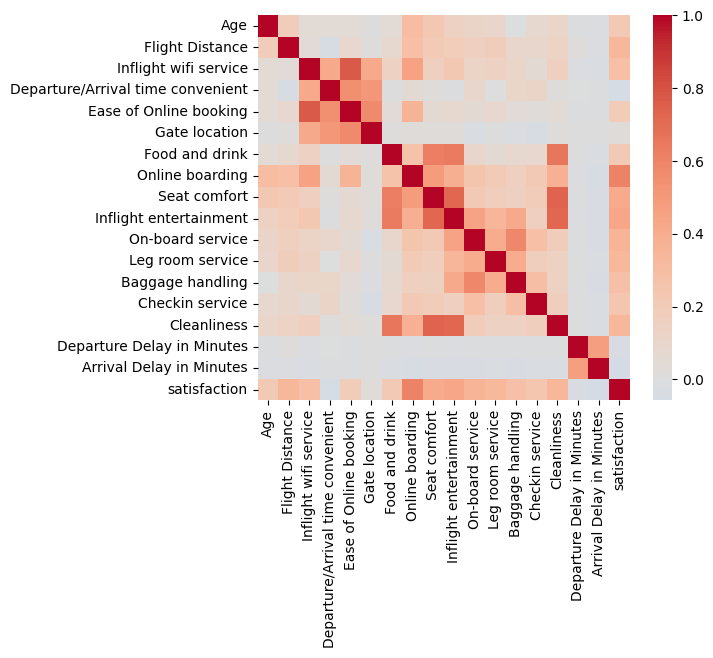

In [148]:
import seaborn as sns, matplotlib.pyplot as plt

num = X.select_dtypes("number").assign(satisfaction=y.astype(int))
corr = num.corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()

## XGB
#### Public LB : 0.95829

In [178]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

def cv_xgb(X_, test_, params, seed=42):
    oof = np.zeros(len(X_)); pred = np.zeros(len(test_)); best = []
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_, y):
        m = XGBClassifier(n_estimators=5000, tree_method="hist", enable_categorical=True,
                          eval_metric="auc", early_stopping_rounds=50, **params)
        m.fit(X_.iloc[tr], y.iloc[tr], eval_set=[(X_.iloc[va], y.iloc[va])], verbose=False)
        oof[va] = m.predict_proba(X_.iloc[va])[:, 1]
        pred += m.predict_proba(test_)[:, 1] / 5
        best.append(m.best_iteration)
    print(f"AUC {roc_auc_score(y, oof):.5f}  best_iters {best}")
    return oof, pred

xgb_params = dict(learning_rate=0.1, max_depth=6, min_child_weight=5,
                  subsample=0.8, colsample_bytree=0.7)
oof_xgb, pred_xgb = cv_xgb(X_c, test_c, xgb_params)

AUC 0.95864  best_iters [377, 339, 350, 352, 324]


In [152]:
sub = pd.DataFrame({"id": test_id, "satisfaction": pred_xgb})
sub.to_csv("submission_xgb.csv", index=False)

## LGBM + XGB Blend
#### LB : 0.95832

In [154]:
from lightgbm import early_stopping

def cv_lgbm(X_, test_, params, seed=42, patience=200):
    oof = np.zeros(len(X_)); pred = np.zeros(len(test_)); best = []
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_, y):
        m = LGBMClassifier(n_estimators=5000, verbose=-1, **params)
        m.fit(X_.iloc[tr], y.iloc[tr], eval_set=[(X_.iloc[va], y.iloc[va])],
              eval_metric="auc", callbacks=[early_stopping(patience, verbose=False)])
        oof[va] = m.predict_proba(X_.iloc[va])[:, 1]
        pred += m.predict_proba(test_)[:, 1] / 5
        best.append(m.best_iteration_)
    print(f"AUC {roc_auc_score(y, oof):.5f}  best_iters {best}")
    return oof, pred

lgb_params = dict(learning_rate=0.1, num_leaves=31, colsample_bytree=0.7,
                  subsample=0.8, subsample_freq=1)
oof_lgb, pred_lgb = cv_lgbm(X_c, test_c, lgb_params, patience=50)

AUC 0.95857  best_iters [217, 251, 315, 523, 348]


In [155]:
print(np.corrcoef(oof_lgb, oof_xgb)[0, 1])
from scipy.stats import rankdata
for w in (0.3, 0.5, 0.7):
    print(w, round(roc_auc_score(y, w * rankdata(oof_lgb) + (1 - w) * rankdata(oof_xgb)), 5))

0.9984372888939909
0.3 0.95885
0.5 0.95888
0.7 0.95882


In [156]:
n = len(pred_lgb)
blend = 0.5 * rankdata(pred_lgb) / n + 0.5 * rankdata(pred_xgb) / n
sub = pd.DataFrame({"id": test_id, "satisfaction": blend})
sub.to_csv("submission_blend.csv", index=False)

## LGBM + XGB + CATBOOST Blend
#### 0.95841

In [164]:
from catboost import CatBoostClassifier

cat_raw = list(X.select_dtypes("category").columns)
Xr = X.copy(); tr_ = test_df.copy()
for c in cat_raw:
    Xr[c] = Xr[c].astype(str); tr_[c] = tr_[c].astype(str)

def cv_cat(X_, test_, params, seed=42):
    oof = np.zeros(len(X_)); pred = np.zeros(len(test_)); best = []
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_, y):
        m = CatBoostClassifier(iterations=2000, eval_metric="AUC", early_stopping_rounds=50,
                               cat_features=cat_raw, verbose=200, **params)
        m.fit(X_.iloc[tr], y.iloc[tr], eval_set=(X_.iloc[va], y.iloc[va]))
        oof[va] = m.predict_proba(X_.iloc[va])[:, 1]
        pred += m.predict_proba(test_)[:, 1] / 5
        best.append(m.get_best_iteration())
    print(f"AUC {roc_auc_score(y, oof):.5f}  best_iters {best}")
    return oof, pred

cat_params = dict(learning_rate=0.15, depth=6, max_ctr_complexity=1, thread_count=-1)
oof_cat, pred_cat = cv_cat(Xr, tr_, cat_params)

0:	test: 0.9349236	best: 0.9349236 (0)	total: 408ms	remaining: 13m 34s
200:	test: 0.9578418	best: 0.9578418 (200)	total: 1m 25s	remaining: 12m 48s
400:	test: 0.9584001	best: 0.9584011 (398)	total: 2m 54s	remaining: 11m 35s
600:	test: 0.9585206	best: 0.9585219 (599)	total: 4m 19s	remaining: 10m 5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9586005142
bestIteration = 740

Shrink model to first 741 iterations.
0:	test: 0.9330774	best: 0.9330774 (0)	total: 689ms	remaining: 22m 58s
200:	test: 0.9565007	best: 0.9565007 (200)	total: 1m 24s	remaining: 12m 38s
400:	test: 0.9570395	best: 0.9570395 (400)	total: 2m 49s	remaining: 11m 14s
600:	test: 0.9572736	best: 0.9572756 (591)	total: 4m 14s	remaining: 9m 51s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9573114515
bestIteration = 622

Shrink model to first 623 iterations.
0:	test: 0.9350014	best: 0.9350014 (0)	total: 408ms	remaining: 13m 36s
200:	test: 0.9585940	best: 0.9585940 (200)	total: 1m 24s	

In [179]:
r = lambda a: rankdata(a) / len(a)
print(np.corrcoef(oof_cat, oof_lgb)[0, 1], np.corrcoef(oof_cat, oof_xgb)[0, 1])
print(round(roc_auc_score(y, (r(oof_lgb) + r(oof_xgb) + r(oof_cat)) / 3), 5))

0.9976579856193224 0.9979950914812546
0.95897


In [166]:
blend = (r(pred_lgb) + r(pred_xgb) + r(pred_cat)) / 3
pd.DataFrame({"id": test_id, "satisfaction": blend}).to_csv("submission_blend3.csv", index=False)